# MINI PROJECT 2 {Exploratory Data Analysis (EDA)on Vehicle Insurance Dataset}

DATA LOADING & INSPECTION

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df=pd.read_csv("/content/Vehicle_Insurance (1).csv")

Q1. Understand the structure of the dataset

In [ ]:
print(df.shape)
print(df.info())
print(df.describe(include="all"))
print(df.isnull().sum())
print(df.duplicated().sum())


(381109, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB
None
                   id  Gender            Age  Driving_License    Region_Code  \


Q2. Identify the types of information available


In [ ]:
print(df.select_dtypes(include=np.number).columns)
print(df.select_dtypes(include="object").columns)

Index(['id', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured',
       'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response'],
      dtype='object')
Index(['Gender', 'Vehicle_Age', 'Vehicle_Damage'], dtype='object')


DATA CLEANING

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.isnull().sum()

,0
id,0
Gender,0
Age,0
Driving_License,0
Region_Code,0
Previously_Insured,0
Vehicle_Age,0
Vehicle_Damage,0
Annual_Premium,0
Policy_Sales_Channel,0


FIXING THE OUTLIER WITH IQR METHOD

In [ ]:
numeric_col=df.select_dtypes(include=["int64","float64"]).columns

In [ ]:
for col in numeric_col:
  Q1=df[col].quantile(0.25)
  Q3=df[col].quantile(0.75)
  IQR=Q3-Q1
  lower=Q1-1.5*IQR
  upper=Q3+1.5*IQR
  mean_val=df[col].mean()
  df[col]=np.where(
      (df[col] < lower) | (df[col] > upper),
      mean_val,
  df[col])

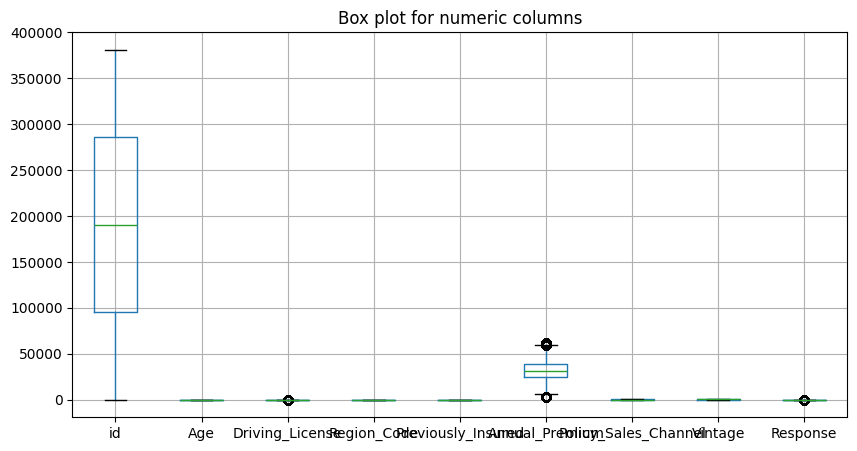

In [ ]:
plt.figure(figsize=(10,5))
df[numeric_col].boxplot()
plt.title("Box plot for numeric columns")
plt.show()

Q3. Handle missing values and outliers appropriately


In [ ]:
print(df.isnull().sum())

id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64


Data Visualization:

Utilize various visualization techniques to explore the distribution of key
variables.


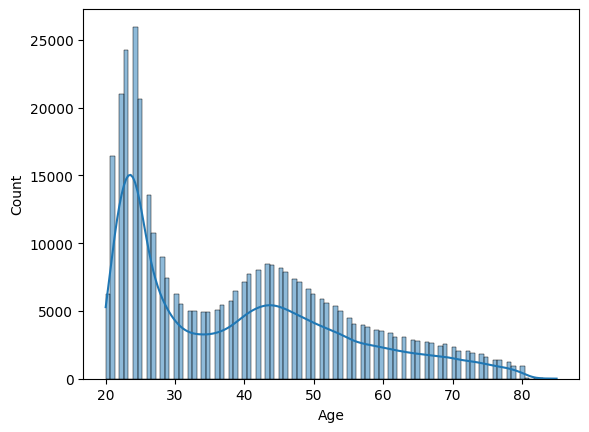

In [ ]:
sns.histplot(df["Age"], kde=True)
plt.show()


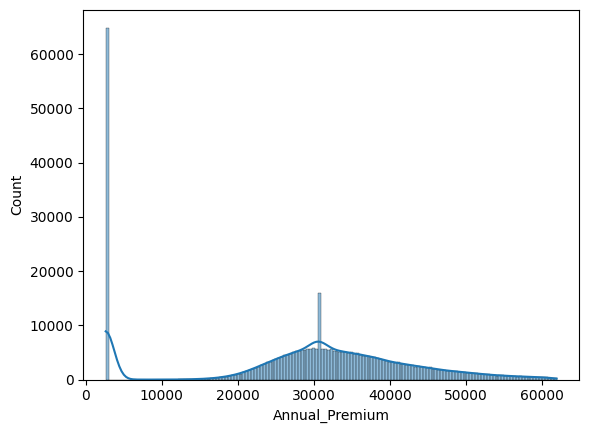

In [ ]:
sns.histplot(df["Annual_Premium"], kde=True)
plt.show()


Feature Analysis:


Examine the relationship between features and the target variable (insurance
claims).

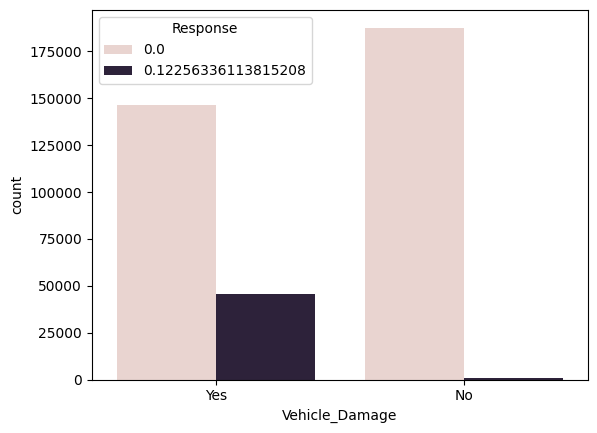

In [ ]:
sns.countplot(x="Vehicle_Damage", hue="Response", data=df)
plt.show()

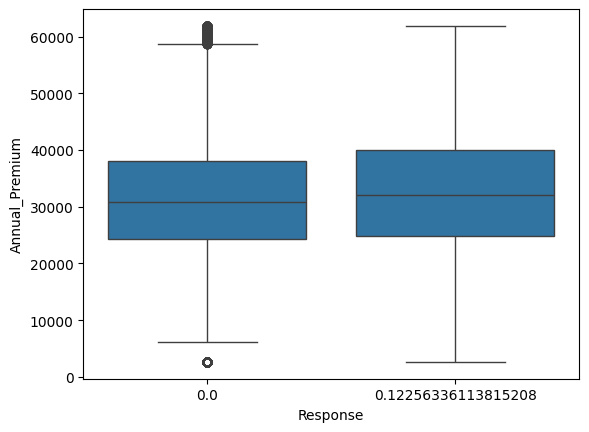

In [ ]:
sns.boxplot(x="Response", y="Annual_Premium", data=df)
plt.show()

Age Distribution:

Analyze the age distribution within the dataset and its impact on insurance
claims.


In [ ]:
age_bins = [20, 30, 40, 50, 60, 70, 80, np.inf]
age_labels = ['20-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80+']
df['Age_Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels, right=False)

age_rate = df.groupby("Age_Group", observed=False)["Response"].mean()
print(age_rate)

Age_Group
20-29    0.005034
30-39    0.024525
40-49    0.026028
50-59    0.021681
60-69    0.014041
70-79    0.009343
80+      0.007675
Name: Response, dtype: float64


Premium Analysis:

Investigate the distribution of insurance premiums and their correlation with
claim frequencies.

                Annual_Premium  Response
Annual_Premium        1.000000  0.018468
Response              0.018468  1.000000


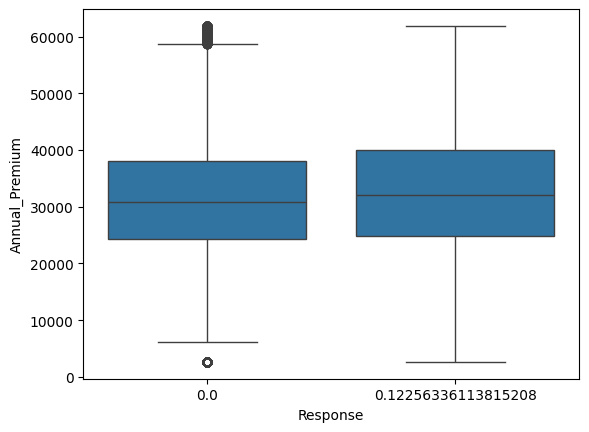

In [ ]:
print(df[["Annual_Premium","Response"]].corr())
sns.boxplot(x="Response", y="Annual_Premium", data=df)
plt.show()

Claim Frequencies:


Explore factors contributing to higher claim frequencies

In [ ]:
for col in ["Gender","Vehicle_Age","Vehicle_Damage","Previously_Insured"]:
  print(df.groupby(col)["Response"].mean().sort_values(ascending=False))

Gender
Male      0.016964
Female    0.012735
Name: Response, dtype: float64
Vehicle_Age
> 2 Years    0.036003
1-2 Year     0.021296
< 1 Year     0.005357
Name: Response, dtype: float64
Vehicle_Damage
Yes    0.029128
No     0.000638
Name: Response, dtype: float64
Previously_Insured
0.0    0.027632
1.0    0.000111
Name: Response, dtype: float64


Gender Analysis:

Investigate the role of gender in insurance claims.

Gender
Female    0.012735
Male      0.016964
Name: Response, dtype: float64


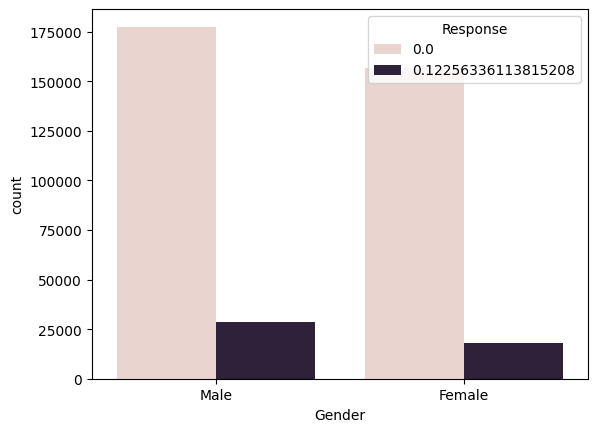

In [ ]:
print(df.groupby("Gender")["Response"].mean())
sns.countplot(x="Gender", hue="Response", data=df)
plt.show()


Vehicle Age and Claims:

Examine the impact of vehicle age on the likelihood of a claim.

In [ ]:
print(df.groupby("Vehicle_Age")["Response"].mean())

Vehicle_Age
1-2 Year     0.021296
< 1 Year     0.005357
> 2 Years    0.036003
Name: Response, dtype: float64


Region-wise Analysis:


Analyze regional patterns in insurance claims.


In [ ]:
region = df.groupby("Region_Code")["Response"].mean().sort_values(ascending=False)
print(region.head(10))


Region_Code
38.0    0.023533
28.0    0.022939
19.0    0.019961
4.0     0.019395
23.0    0.018760
51.0    0.018753
24.0    0.017357
7.0     0.016147
18.0    0.016126
3.0     0.015647
Name: Response, dtype: float64


Policy Analysis:

Explore the distribution and impact of different insurance policy types.

In [ ]:
channel = df.groupby("Policy_Sales_Channel")["Response"].mean()
print(channel.sort_values(ascending=False).head(10))


Policy_Sales_Channel
43.0     0.122563
123.0    0.122563
28.0     0.040854
27.0     0.040854
36.0     0.040069
155.0    0.039232
163.0    0.037282
3.0      0.037261
121.0    0.036386
81.0     0.035018
Name: Response, dtype: float64


Claim Frequency by Vehicle Damage:


Investigate the relationship between vehicle damage and claim frequencies

Vehicle_Damage
No     0.000638
Yes    0.029128
Name: Response, dtype: float64


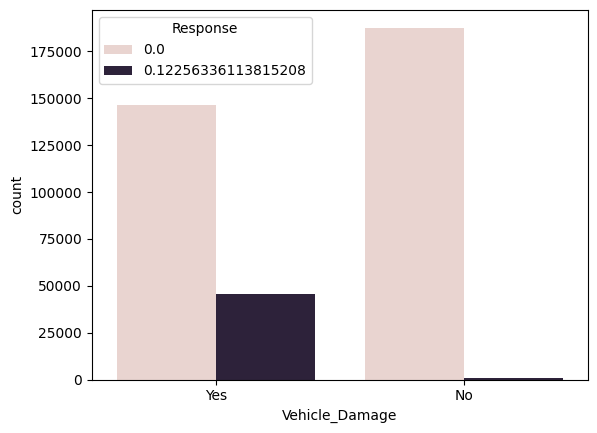

In [ ]:
print(df.groupby("Vehicle_Damage")["Response"].mean())
sns.countplot(x="Vehicle_Damage", hue="Response", data=df)
plt.show()


Customer Loyalty:

Analyze if the number of policies held by a customer influences claim
likelihood.


In [ ]:

vintage_bins = [0, 50, 100, 150, 200, 250, 300]
vintage_labels = ['0-50', '51-100', '101-150', '151-200', '201-250', '251-300']
df['Vintage_Group'] = pd.cut(df['Vintage'], bins=vintage_bins, labels=vintage_labels, right=False)

print(df.groupby("Vintage_Group", observed=False)["Response"].mean())

Vintage_Group
0-50       0.015291
51-100     0.014780
101-150    0.015099
151-200    0.014974
201-250    0.015189
251-300    0.014852
Name: Response, dtype: float64


Time Analysis:

if applicable, explore temporal patterns in insurance claims.


In [ ]:
print(df["Vintage"].describe())

count    381109.000000
mean        154.347397
std          83.671304
min          10.000000
25%          82.000000
50%         154.000000
75%         227.000000
max         299.000000
Name: Vintage, dtype: float64


VISUALIZATION

1. Overall Response Distribution


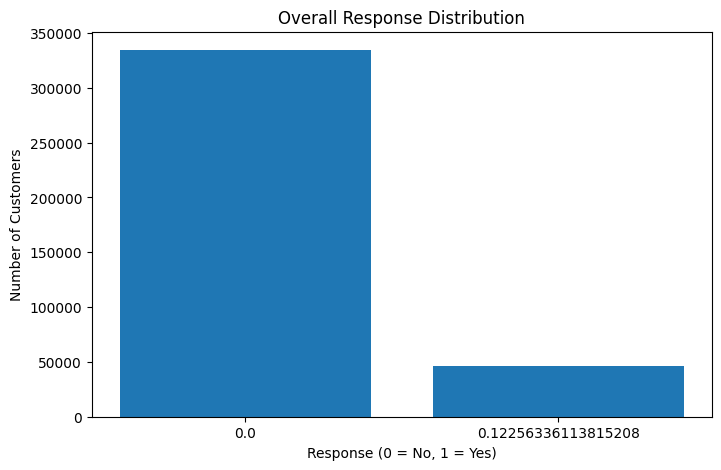

In [ ]:
response_count = df["Response"].value_counts().sort_index()
plt.figure(figsize=(8, 5))
plt.bar(response_count.index.astype(str), response_count.values)
plt.title("Overall Response Distribution")
plt.xlabel("Response (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

2. Age Distribution

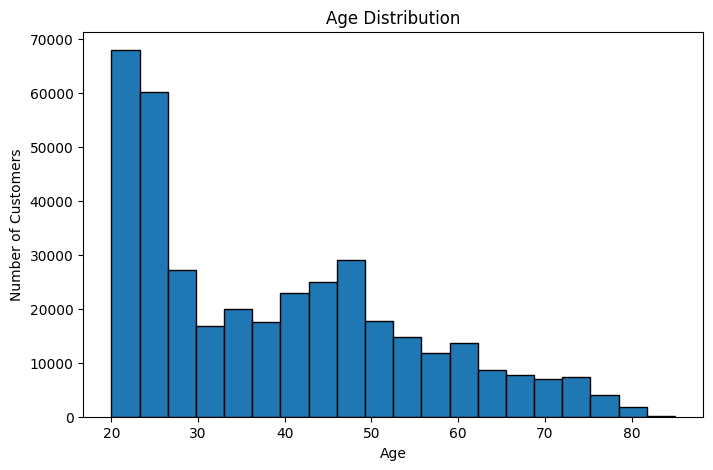

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["Age"], bins=20, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

3. Age by Response

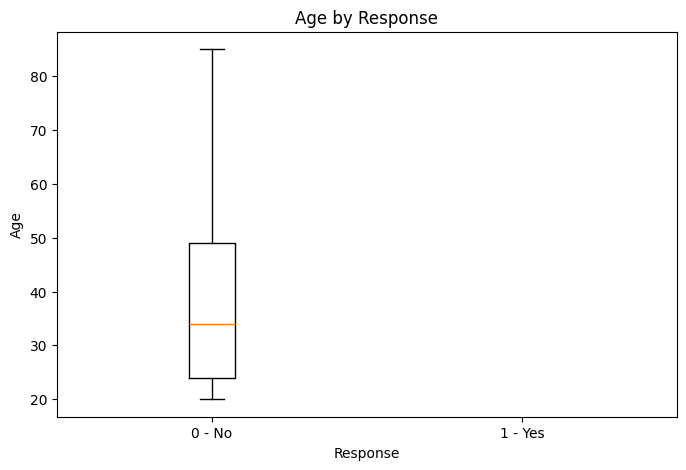

In [ ]:
age_data = [
df.loc[df["Response"] == 0, "Age"],
df.loc[df["Response"] == 1, "Age"]
]
plt.figure(figsize=(8, 5))
plt.boxplot(age_data, tick_labels=["0 - No", "1 - Yes"])
plt.title("Age by Response")
plt.xlabel("Response")
plt.ylabel("Age")
plt.show()

4.	Gender Distribution

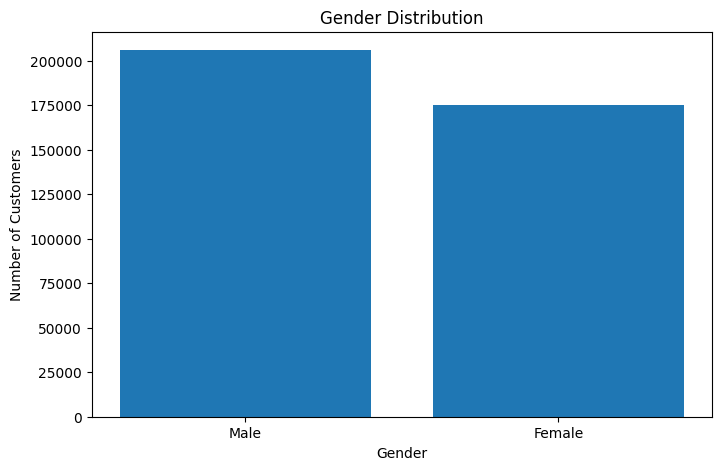

In [ ]:
gender_count = df["Gender"].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(gender_count.index, gender_count.values)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

5. Gender vs Respon

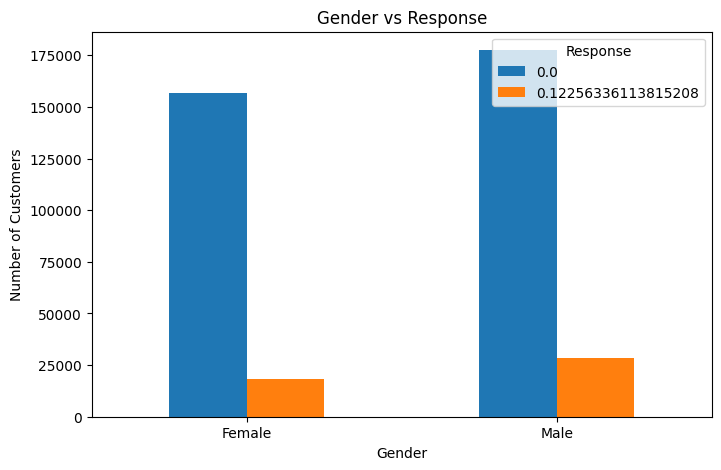

In [ ]:
gender_response = pd.crosstab(df["Gender"], df["Response"])
gender_response.plot(kind="bar", figsize=(8, 5))
plt.title("Gender vs Response")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Response")
plt.show()

6. Response Rate by Gender

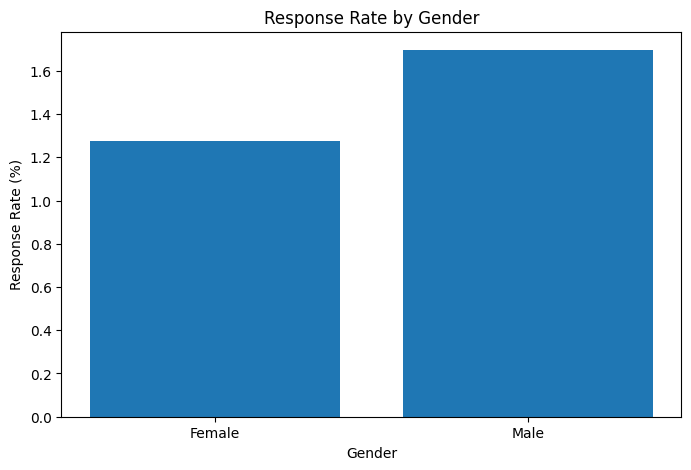

In [ ]:
gender_rate = df.groupby("Gender")["Response"].mean() * 100
plt.figure(figsize=(8, 5))
plt.bar(gender_rate.index, gender_rate.values)
plt.title("Response Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Response Rate (%)")
plt.show()

7. Vehicle Age vs Response



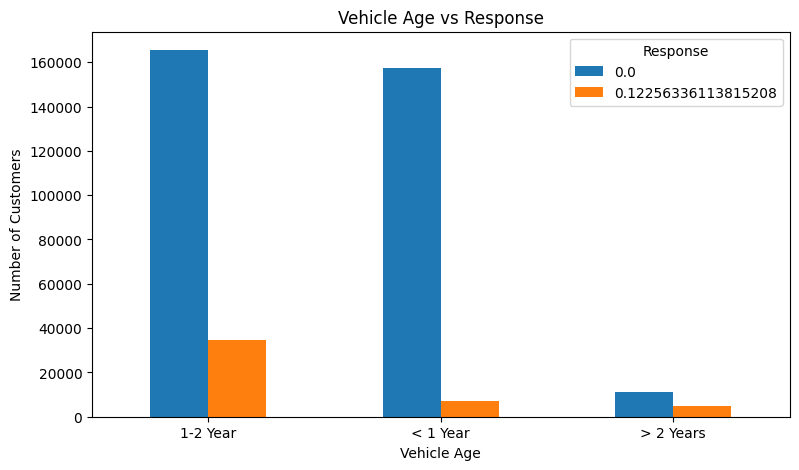

In [ ]:
vehicle_age_response = pd.crosstab(df["Vehicle_Age"], df["Response"])
vehicle_age_response.plot(kind="bar", figsize=(9, 5))
plt.title("Vehicle Age vs Response")
plt.xlabel("Vehicle Age")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Response")
plt.show()

8. Response Rate by Vehicle Age

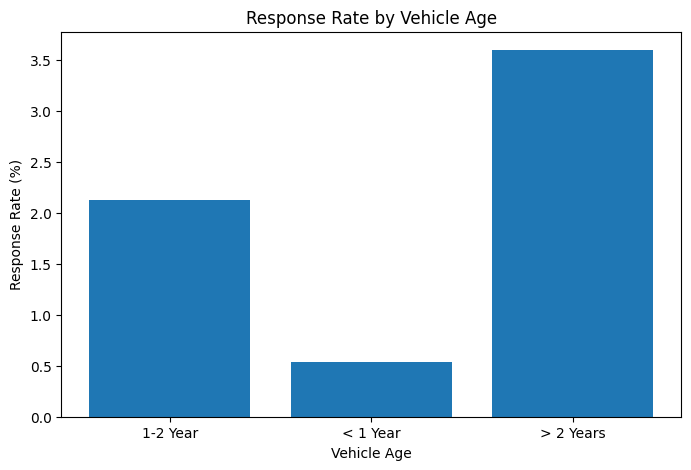

In [ ]:
vehicle_age_rate = df.groupby("Vehicle_Age")["Response"].mean() * 100
plt.figure(figsize=(8, 5))
plt.bar(vehicle_age_rate.index, vehicle_age_rate.values)
plt.title("Response Rate by Vehicle Age")
plt.xlabel("Vehicle Age")
plt.ylabel("Response Rate (%)")
plt.show()

9. Vehicle Damage vs Response

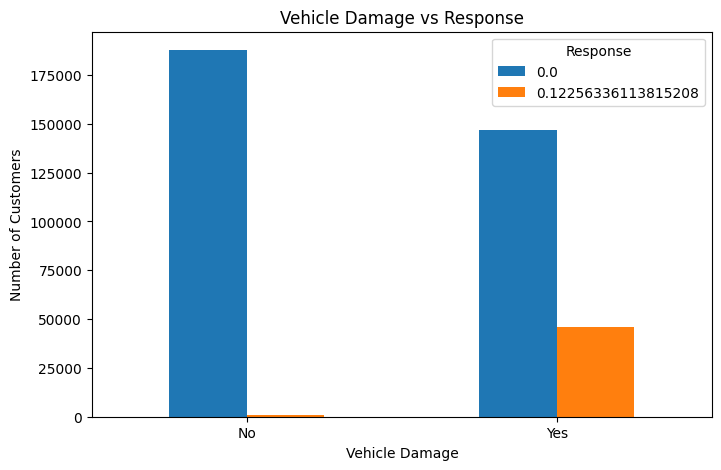

In [ ]:
damage_response = pd.crosstab(df["Vehicle_Damage"], df["Response"])
damage_response.plot(kind="bar", figsize=(8, 5))
plt.title("Vehicle Damage vs Response")
plt.xlabel("Vehicle Damage")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Response")
plt.show()

10. Response Rate by Vehicle Damage

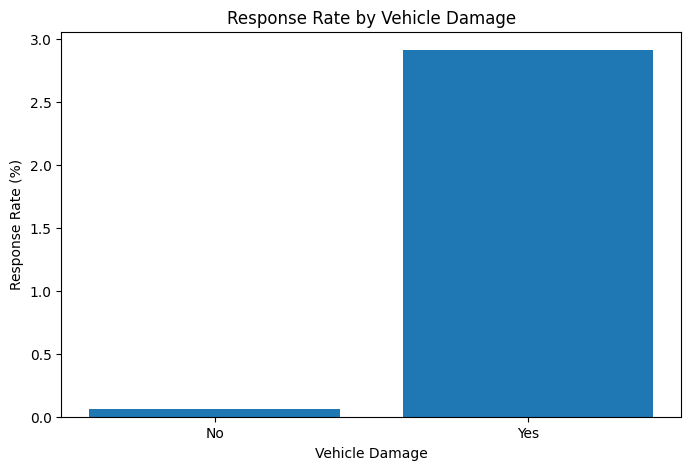

In [ ]:
damage_rate = df.groupby("Vehicle_Damage")["Response"].mean() * 100
plt.figure(figsize=(8, 5))
plt.bar(damage_rate.index, damage_rate.values)
plt.title("Response Rate by Vehicle Damage")
plt.xlabel("Vehicle Damage")
plt.ylabel("Response Rate (%)")
plt.show()

11. Annual Premium Distribution


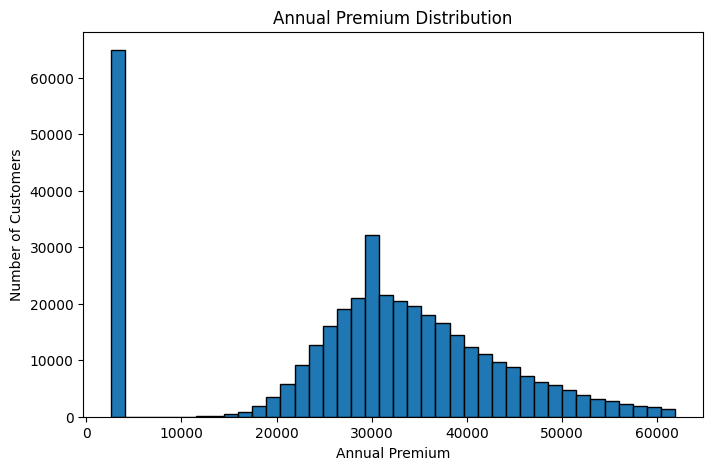

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["Annual_Premium"], bins=40, edgecolor="black")
plt.title("Annual Premium Distribution")
plt.xlabel("Annual Premium")
plt.ylabel("Number of Customers")
plt.show()

12. Premium by Response


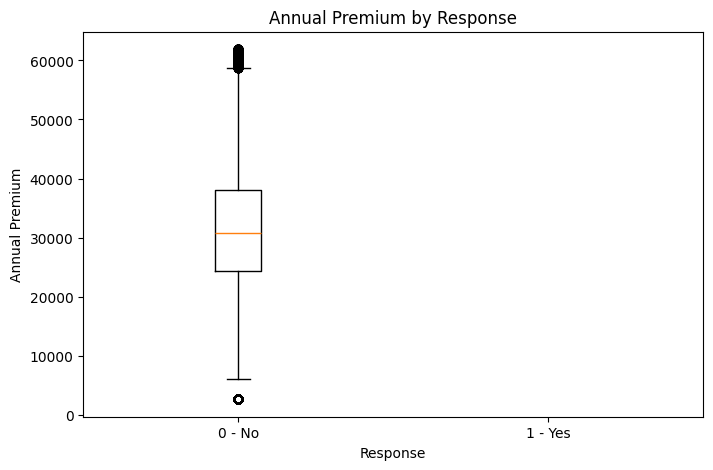

In [ ]:
premium_data = [
df.loc[df["Response"] == 0, "Annual_Premium"],
df.loc[df["Response"] == 1, "Annual_Premium"]
]
plt.figure(figsize=(8, 5))
plt.boxplot(premium_data, tick_labels=["0 - No", "1 - Yes"])
plt.title("Annual Premium by Response")
plt.xlabel("Response")
plt.ylabel("Annual Premium")
plt.show()

13. Age vs Annual Premium

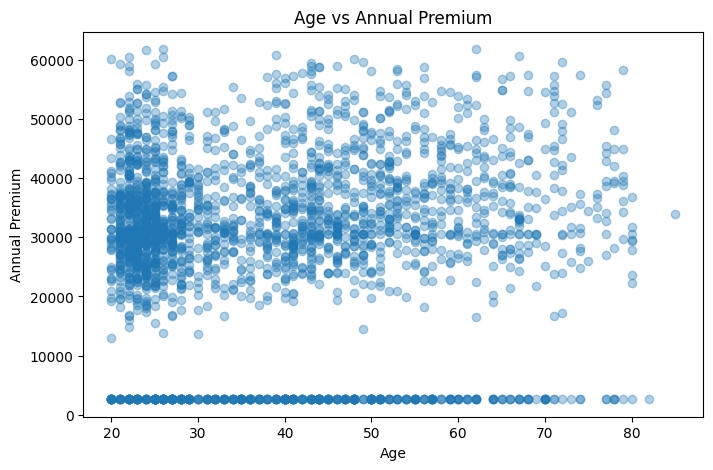

In [ ]:
sample_df = df.sample(min(2500, len(df)), random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(sample_df["Age"], sample_df["Annual_Premium"], alpha=0.35)
plt.title("Age vs Annual Premium")
plt.xlabel("Age")
plt.ylabel("Annual Premium")
plt.show()

14. Annual Premium vs Vintage

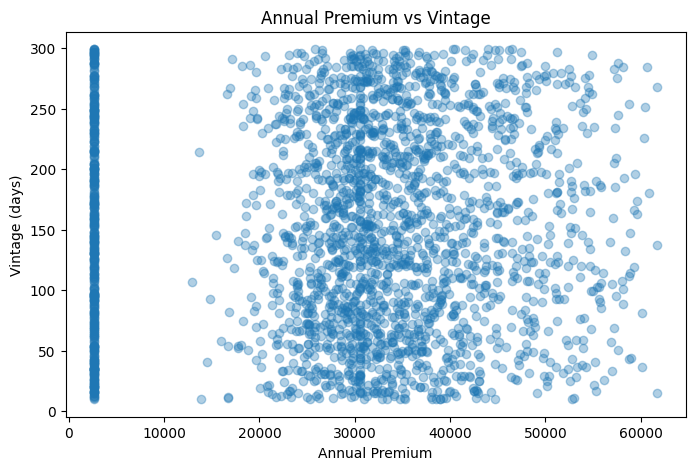

In [ ]:
sample_df = df.sample(min(2500, len(df)), random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(sample_df["Annual_Premium"], sample_df["Vintage"], alpha=0.35)
plt.title("Annual Premium vs Vintage")
plt.xlabel("Annual Premium")
plt.ylabel("Vintage (days)")
plt.show()

15. Response Rate by Age Group

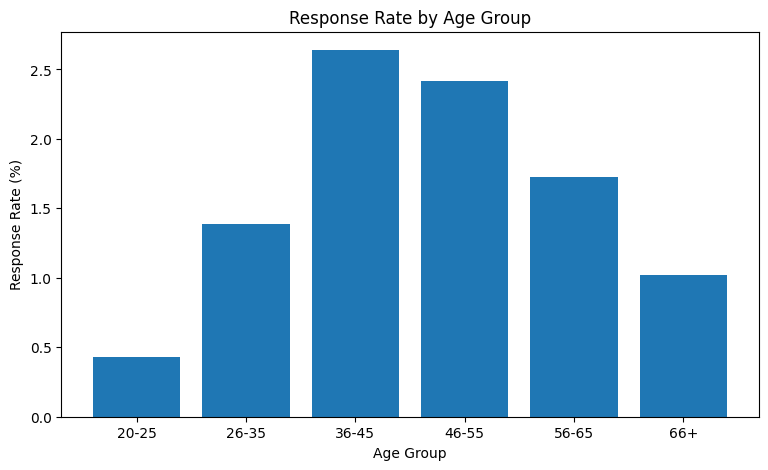

In [ ]:
df["Age_Group"] = pd.cut(
df["Age"],
bins=[19, 25, 35, 45, 55, 65, 100],
labels=["20-25", "26-35", "36-45", "46-55", "56-65", "66+"]
)
age_group_rate = df.groupby("Age_Group", observed=False)["Response"].mean() * 100
plt.figure(figsize=(9, 5))
plt.bar(age_group_rate.index.astype(str), age_group_rate.values)
plt.title("Response Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Response Rate (%)")
plt.show()

16. Top 15 Regions by Response Rate

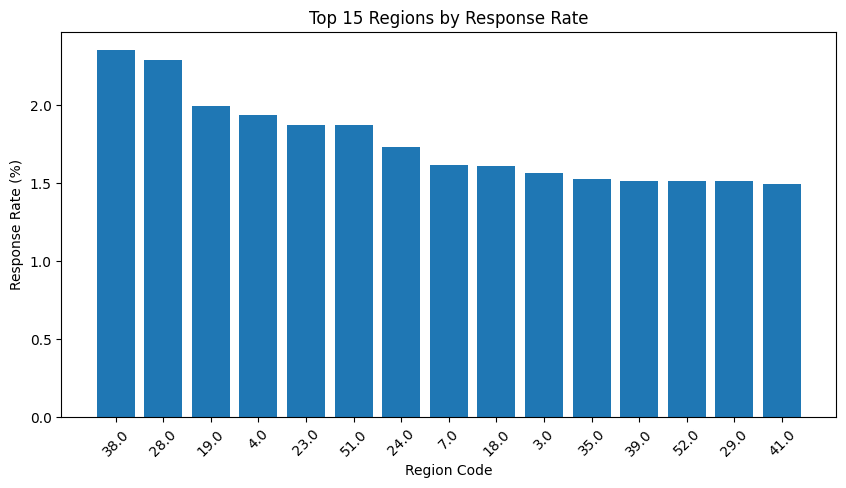

In [ ]:
region_rate = (
df.groupby("Region_Code")["Response"]
.mean()
.sort_values(ascending=False)
.head(15) * 100
)
plt.figure(figsize=(10, 5))
plt.bar(region_rate.index.astype(str), region_rate.values)
plt.title("Top 15 Regions by Response Rate")
plt.xlabel("Region Code")
plt.ylabel("Response Rate (%)")
plt.xticks(rotation=45)
plt.show()

17. Top 10 Policy Sales Channels by Response Rate

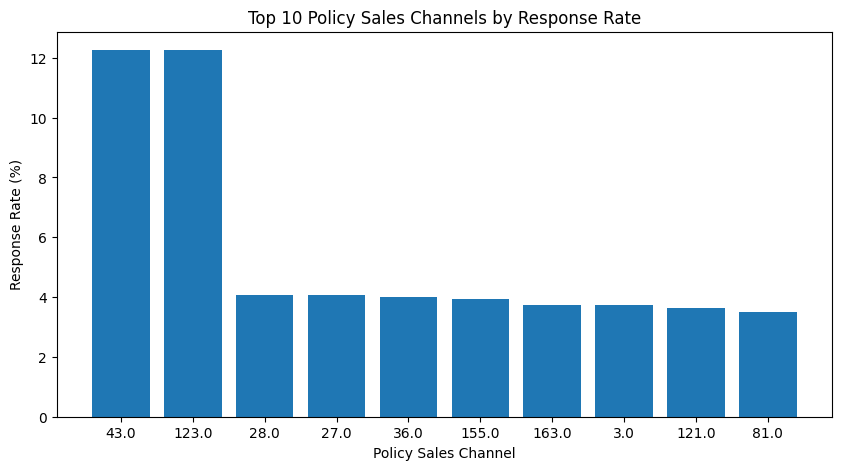

In [ ]:
channel_rate = (
df.groupby("Policy_Sales_Channel")["Response"]
.mean()
.sort_values(ascending=False)
.head(10) * 100
)
plt.figure(figsize=(10, 5))
plt.bar(channel_rate.index.astype(str), channel_rate.values)
plt.title("Top 10 Policy Sales Channels by Response Rate")
plt.xlabel("Policy Sales Channel")
plt.ylabel("Response Rate (%)")
plt.show()

18. Previous Insurance vs Response

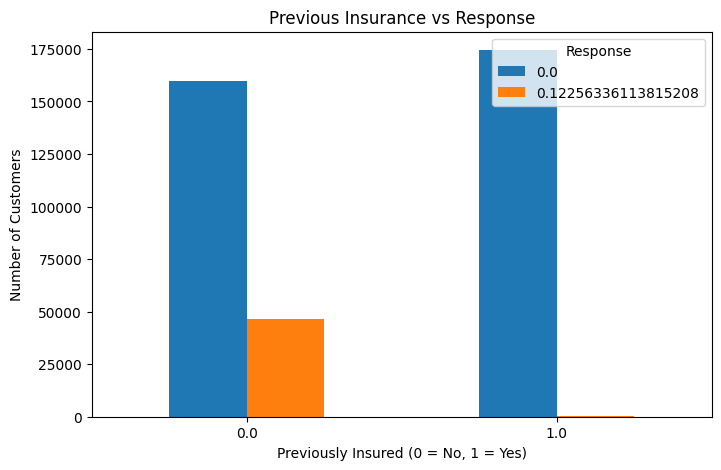

In [ ]:
previous_insurance = pd.crosstab(
df["Previously_Insured"],
df["Response"]
)
previous_insurance.plot(kind="bar", figsize=(8, 5))
plt.title("Previous Insurance vs Response")
plt.xlabel("Previously Insured (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Response")
plt.show()

19. Response Rate by Previous Insurance Status

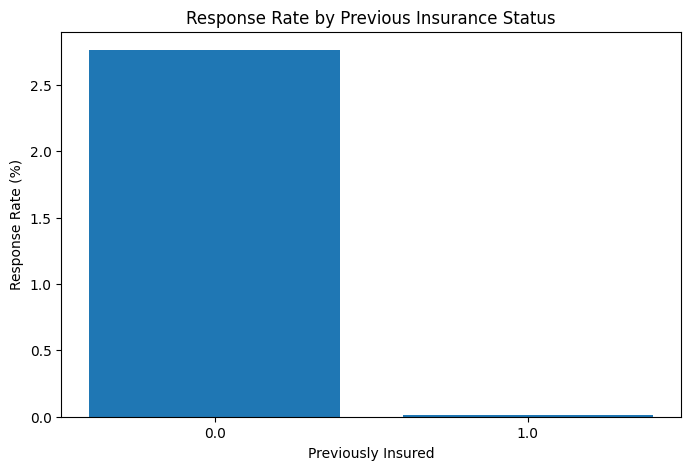

In [ ]:
previous_rate = df.groupby("Previously_Insured")["Response"].mean() * 100
plt.figure(figsize=(8, 5))
plt.bar(previous_rate.index.astype(str), previous_rate.values)
plt.title("Response Rate by Previous Insurance Status")
plt.xlabel("Previously Insured")
plt.ylabel("Response Rate (%)")
plt.show()

20. Driving License vs Response

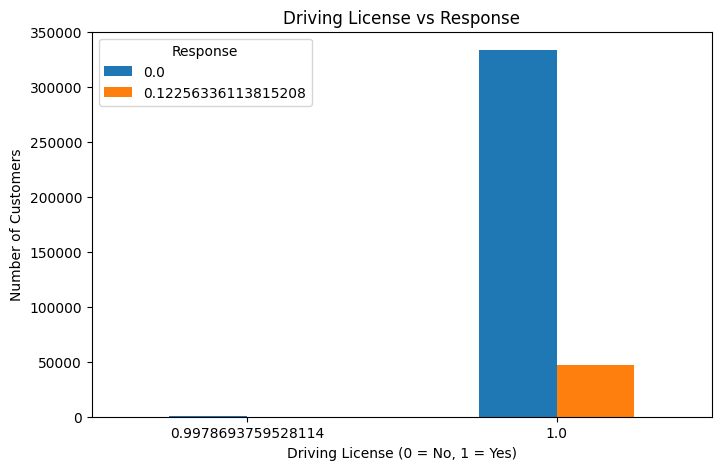

In [ ]:
license_response = pd.crosstab(
df["Driving_License"],
df["Response"]
)
license_response.plot(kind="bar", figsize=(8, 5))
plt.title("Driving License vs Response")
plt.xlabel("Driving License (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Response")
plt.show()

21. Customer Vintage Distribution

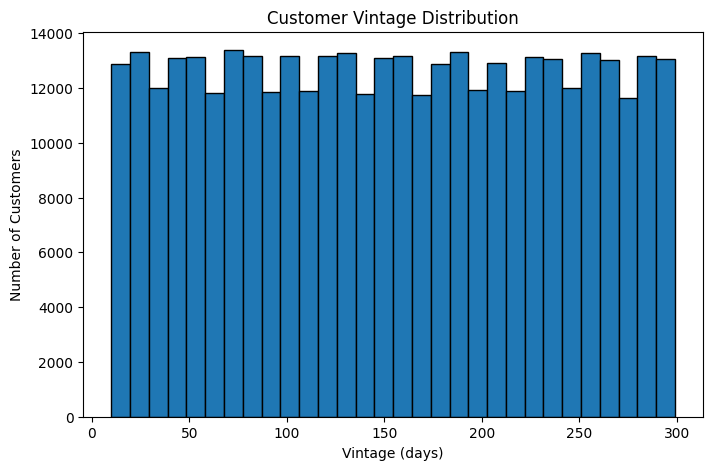

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["Vintage"], bins=30, edgecolor="black")
plt.title("Customer Vintage Distribution")
plt.xlabel("Vintage (days)")
plt.ylabel("Number of Customers")
plt.show()

22. Response Rate by Vintage Group

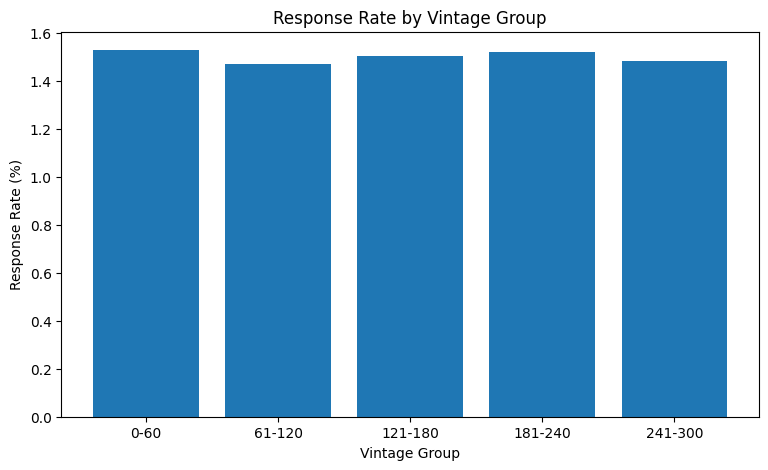

In [ ]:
df["Vintage_Group"] = pd.cut(
df["Vintage"],
bins=[0, 60, 120, 180, 240, 300],
labels=["0-60", "61-120", "121-180", "181-240", "241-300"]
)
vintage_rate = (
df.groupby("Vintage_Group", observed=False)["Response"].mean() * 100
)
plt.figure(figsize=(9, 5))
plt.bar(vintage_rate.index.astype(str), vintage_rate.values)
plt.title("Response Rate by Vintage Group")
plt.xlabel("Vintage Group")
plt.ylabel("Response Rate (%)")
plt.show()

23. Numerical Correlation Heatmap

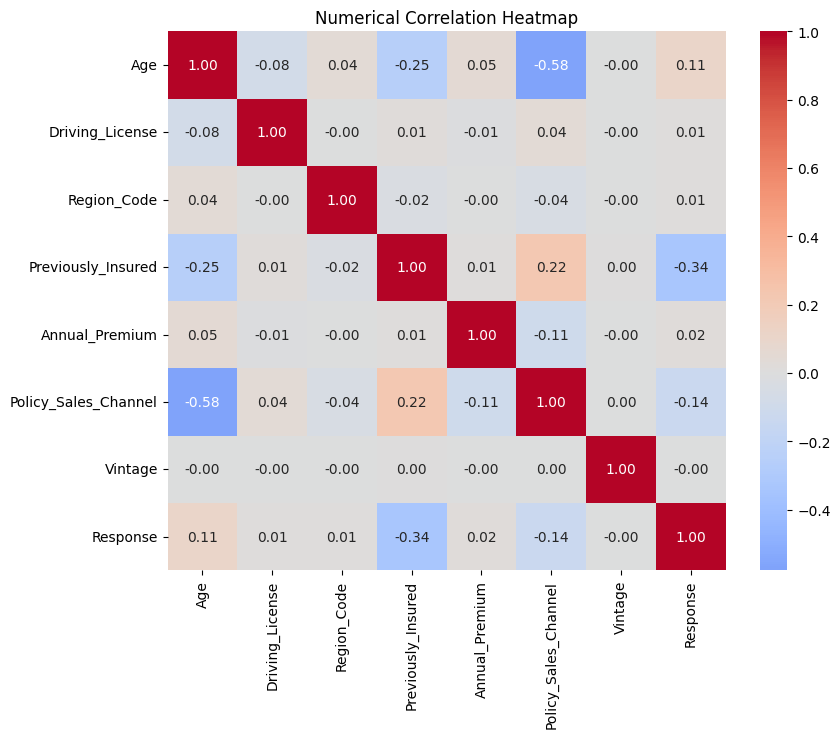

In [ ]:
numeric_columns = [
"Age", "Driving_License", "Region_Code",
"Previously_Insured", "Annual_Premium",
"Policy_Sales_Channel", "Vintage", "Response"
]
correlation = df[numeric_columns].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(
correlation,
annot=True,
fmt=".2f",
cmap="coolwarm",
center=0
)
plt.title("Numerical Correlation Heatmap")
plt.show()

24. Premium Band vs Response


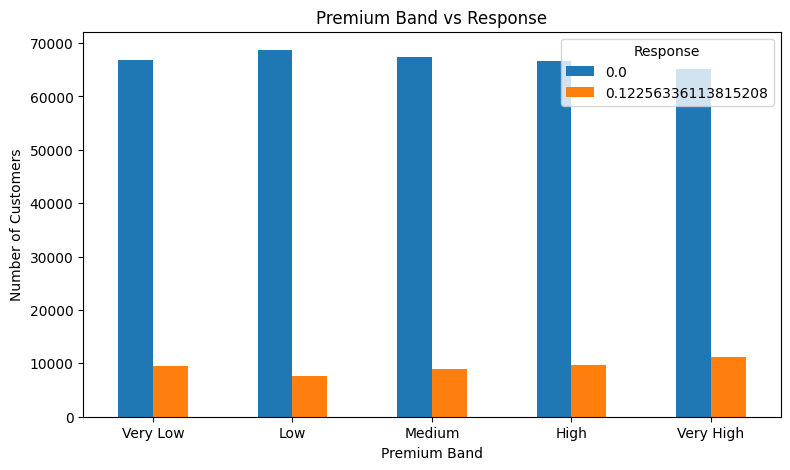

In [ ]:
df["Premium_Band"] = pd.qcut(
df["Annual_Premium"],
q=5,
labels=["Very Low", "Low", "Medium", "High", "Very High"],
duplicates="drop"
)
premium_response = pd.crosstab(
df["Premium_Band"],
df["Response"]
)
premium_response.plot(kind="bar", figsize=(9, 5))
plt.title("Premium Band vs Response")
plt.xlabel("Premium Band")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Response")
plt.show()

25. Response Rate: Age Group x Vehicle Damage


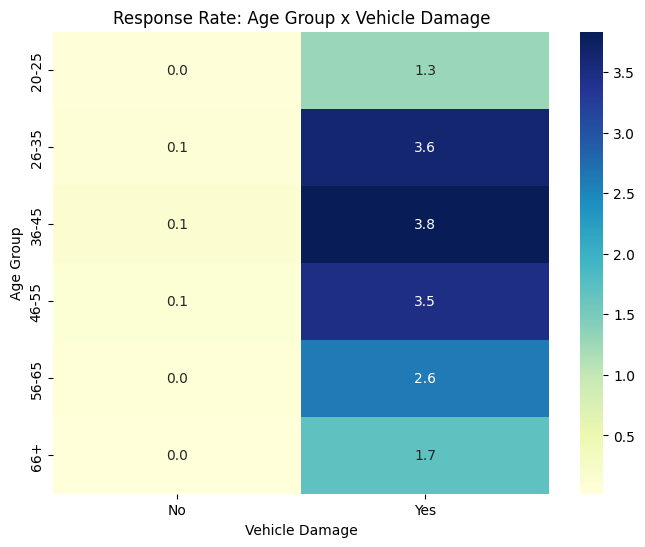

In [ ]:
age_damage = pd.crosstab(
df["Age_Group"],
df["Vehicle_Damage"],
values=df["Response"],
aggfunc="mean"
) * 100
plt.figure(figsize=(8, 6))
sns.heatmap(
age_damage,
annot=True,
fmt=".1f",
cmap="YlGnBu"
)
plt.title("Response Rate: Age Group x Vehicle Damage")
plt.xlabel("Vehicle Damage")
plt.ylabel("Age Group")
plt.show()

>> Key Findings & Business Insights

• Overall response rate: 12.0%.


• Highest-response vehicle-damage category: Yes.


• Highest-response vehicle-age category: > 2 Years.


• Highest-response age group: 66+.


• Leading region in the top-15 comparison: 10.


• Leading sales channel in the top-10 comparison: 55.


• Annual premium is right-skewed; robust statistics and outlier inspection are recommended.


• Previous insurance status and vehicle damage are strong segmentation variables in this analysis.


• Direct policy-count and policy-date fields are absent, so those requested analyses cannot be performed directly without
additional columns.


>>Conclusion

The project completes the major EDA requirements in the supplied brief: data loading and inspection, cleaning,
visualization, feature analysis, age analysis, premium analysis, claim/response analysis, gender analysis, vehicle-age
analysis, region-wise analysis, policy/sales-channel analysis, vehicle-damage analysis, customer-tenure analysis and
applicability checks for time analysis

In [ ]:
df.to_csv("cleaned_mini.csv",index=False)

In [ ]:
from google.colab import files
files.download("cleaned_mini.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>